In [1]:
import numpy as np
import matplotlib.pyplot as plt
import animation
import sys
np.random.seed(0)

In [2]:
def construct_lap_dirichlet(nx):
    '''Construct laplacian operator with dirichlet BCs (zeros in corners)'''
    
    lap = -2*np.diag(np.ones(nx)) + 1*np.diag(np.ones(nx-1), 1) + 1*np.diag(np.ones(nx-1), -1)

    
    return lap

def construct_lap_periodic(nx):
    '''Construct laplacian operator with periodic BCs'''
    
    lap = -2*np.diag(np.ones(nx)) + 1*np.diag(np.ones(nx-1), 1) + 1*np.diag(np.ones(nx-1), -1)
    
    lap[0,-1] = 1    # Periodic BCs
    lap[-1,0] = 1 
    
    return lap

In [3]:
# iteration params
dt = 0.00001
nt = 200000

dx = .10625*2.0 # near the boundary
nx = 100
x = np.linspace(0, dx*nx, nx)

# PDE params
r = 10.0
# qc = 3
qc = np.pi/(dx*nx) * 5

b3 = 0.1 
b5 = 0.1

kappa_e = 1.0
kappa_k = 6.0

beta_e = 5
d_e = 30

params = (r, qc, b3, b5, kappa_k, kappa_e, beta_e, d_e)
u0 = np.random.rand(nx) * .01 - .01/2
e0 = np.ones(nx) * 0.05

# u0 = u_stored[:,-1]
# e0 = e_stored[:,-1]

# integrate forward in time
def integrate_explicit(u0, e0, params, nx, dx, nt, dt, bc='dirichlet'):
    '''Integrate SH35 coupled to expander according to explicit Euler.'''
    
    r, qc, b3, b3, kappa_k, kappa_e, beta_e, d_e = params
    if bc=='dirichlet':
        lap_op = construct_lap_dirichlet(nx) / dx**2
    elif bc=='periodic':
        lap_op = construct_lap_periodic(nx) / dx**2
    qc_op = np.eye(nx) * qc
    
    # d = 1
    # lap_op_2 = lap_op * d # new diffusive operator
    
    # initialize fields
    u_stored = np.zeros((nx, nt))
    u_stored[:,0] = u0
    
    e_stored = np.zeros((nx, nt))
    e_stored[:,0] = e0
    
    # step forward in time
    for i in range(1, nt):
        
        if int(100*i/nt) > int(100*(i-1)/nt):
            sys.stdout.write("\rIteration {0}/{1} ({2}%)".format(i, nt, int(100*i/nt)))
            sys.stdout.flush()
            
        u = u_stored[:,i-1]
        e = e_stored[:,i-1]
        
        # update q_c due to coupling with E
        # reg = 0.01 # regularizer
        qc = kappa_k * e
        qc_op = np.eye(nx) * qc
        
        # update e
        nonlin = kappa_e * np.abs(u)
        e_stored[:,i] = e + dt*(nonlin - beta_e*e + d_e*lap_op@e) + np.random.normal(loc=0.0, scale=0.005*0, size=nx)
        
        # print(alpha_e)
        # print(nonlin)
        
            
        # update u
        nonlin = b3*u**3 - b5*u**5
        harmonic_op = np.linalg.matrix_power(qc_op@qc_op + lap_op, 2) #+ lap_op_2
        
        u_stored[:,i] = u + dt*(r*u - harmonic_op@u + nonlin) + np.random.normal(loc=0.0, scale=.05*0, size=nx)
        if bc=='dirichlet': 
            u_stored[0,i] = 0; u_stored[-1,i] = 0  
            e_stored[0,i] = 0; e_stored[-1,i] = 0  
    
        # if i==1:
        #     print(r*u)
        #     print(-harmonic_op@u)
        
    return u_stored, e_stored


In [190]:
u_stored, e_stored = integrate_explicit(u0, e0, params, nx, dx, nt, dt, bc='dirichlet')

Iteration 198000/200000 (99%)

In [194]:
# plt.plot(e_stored[:,8000])
# plt.show()
animation.animate_2d_array(e_stored[:,::3500])

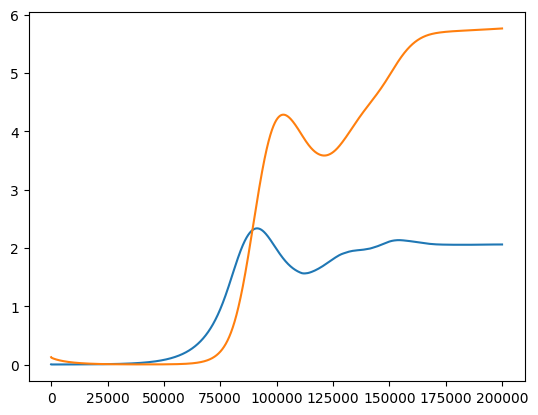

[0.         0.19727748 0.39373558 0.5869854  0.77378548 0.95072001
 1.11479117 1.26385253 1.39682003 1.51364483 1.61508694 1.70236183
 1.77675272 1.83930009 1.89068747 1.93141668 1.96229277 1.9851289
 2.00346292 2.02300255 2.05155783 2.09267051 2.13725497 2.1774016
 2.20759293 2.22555493 2.23272303 2.2343699  2.2392095  2.2582729
 2.28566636 2.31141758 2.32861585 2.33436602 2.33010854 2.32147793
 2.31760897 2.32976461 2.34965633 2.36762502 2.3772777  2.37629847
 2.36666054 2.35439708 2.34882356 2.36091698 2.37953696 2.39547884
 2.40288025 2.40000332 2.38946443 2.37799651 2.37557545 2.38837635
 2.40520237 2.41724361 2.41950062 2.41151823 2.39753267 2.38601086
 2.38837328 2.400576   2.4117549  2.41445086 2.40580589 2.38799014
 2.36798861 2.3565741  2.35956689 2.36485996 2.36322007 2.34978603
 2.32467784 2.29293318 2.26377394 2.24904318 2.24145056 2.23036617
 2.20863626 2.17331981 2.1257052  2.07092223 2.01714156 1.97429032
 1.94010959 1.90522119 1.86246533 1.8071123  1.73647106 1.6492206

In [193]:
plt.plot(np.mean(abs(u_stored), axis=0))
plt.plot(np.mean(e_stored**2*50, axis=0))

# plt.plot(kappa_e * u_stored[:,-1]**2 * e_stored[:,-1])
# plt.hlines(alpha_e, xmin=0, xmax=100)
plt.show()

print(kappa_k * e_stored[:,-1])

Need to find something about SH that scales with k, so that it only oscillates once no matter the L.

Alternatively find something scaling with L.

<br>

for $u~sin(kx)$, 

$<u^2>\sim1$ (constant, doesn't work)

$<\theta( u - u_0 )> \sim 1 $ (also constant)


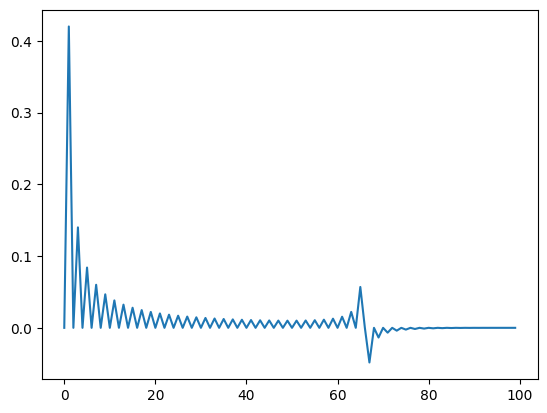

In [327]:
n = [i for i in range(100)]
qc = np.pi/(dx*nx)

y3avg = []
for i in n:
    y = np.sin(qc*x*i)
    # y2avg.append(np.mean(y**2)) # constant with n
    
    # y2avg.append(np.mean(y>0)) # also pretty much constant
    
    y3avg.append(np.mean(y**3)) 
    
    

plt.plot(n, y3avg)
plt.show()

Try to understand dynamics of E better. Set u to a constant sin function, find what E approaches for various values of L.

In [183]:
# iteration params
dt = 0.00001
nt = 30000

dx = .10625*2.0 # near the boundary
nx = 100
x = np.linspace(0, dx*nx, nx)

# PDE params
r = 1.0
# qc = 3
qc = np.pi/(dx*nx) * 5

b3 = 0.1 
b5 = 0.1

kappa_e = 1.0
kappa_k = 6.0

beta_e = 5
d_e = 100

params = (r, qc, b3, b5, kappa_k, kappa_e, beta_e, d_e)
u0 = np.sin(qc*x)
e0 = np.ones(nx) * 0.12

# u0 = u_stored[:,-1]
e0 = e_stored[:,-1]

# integrate forward in time
def integrate_e_explicit(u0, e0, params, nx, dx, nt, dt, bc='dirichlet'):
    '''Integrate SH35 coupled to expander according to explicit Euler.
    Keep u constant to evaluate effects on fast expander.
    '''
    
    r, qc, b3, b3, kappa_k, kappa_e, beta_e, d_e = params
    if bc=='dirichlet':
        lap_op = construct_lap_dirichlet(nx) / dx**2
    elif bc=='periodic':
        lap_op = construct_lap_periodic(nx) / dx**2
    qc_op = np.eye(nx) * qc
    
    
    # initialize fields
    e_stored = np.zeros((nx, nt))
    e_stored[:,0] = e0
    
    # step forward in time
    for i in range(1, nt):
        
        if int(100*i/nt) > int(100*(i-1)/nt):
            sys.stdout.write("\rIteration {0}/{1} ({2}%)".format(i, nt, int(100*i/nt)))
            sys.stdout.flush()
            
        e = e_stored[:,i-1]
        
        # update q_c due to coupling with E
        # reg = 0.01 # regularizer
        qc = kappa_k * e
        qc_op = np.eye(nx) * qc
        
        # update e
        nonlin = kappa_e * np.abs(u0)
        e_stored[:,i] = e + dt*(nonlin - beta_e*e + d_e*lap_op@e) + np.random.normal(loc=0.0, scale=0.005*0, size=nx)
        
        # print(alpha_e)
        # print(nonlin)
        
            
        # update u - removed

        if bc=='dirichlet': 
            e_stored[0,i] = 0; e_stored[-1,i] = 0  
        
    return u0, e_stored

In [184]:
u, e_stored = integrate_e_explicit(u0, e0, params, nx, dx, nt, dt, bc='periodic')

Iteration 29700/30000 (99%)

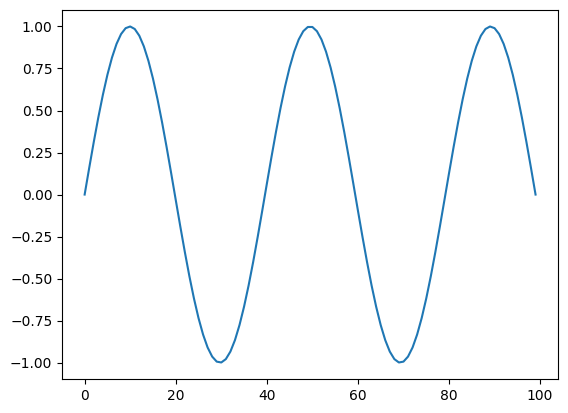

0.01260704277041129
0.12603679608403678


In [301]:
plt.plot(u0)
plt.show()
print(np.mean(np.gradient(u0)**2))
# plt.plot(np.mean(e_stored, axis=0))
# plt.show()
print(np.mean(e_stored[:,-1]))
animation.animate_2d_array(e_stored[:,::3000])

#### 5/26: Try coupling E to space derivatives of u.

In [174]:
# iteration params
dt = 0.00001
nt = 30000

dx = .1
nx = 100
x = np.linspace(0, dx*nx, nx, endpoint=False)

# PDE params
r = 5.0
# qc = 3
qc = np.pi/(dx*nx) * 6
qc_star = qc

b3 = 0.1 
b5 = 0.1

kappa_e = 1.0
kappa_k = 1.0

beta_e = 5
d_e = 200

params = (r, qc, b3, b5, kappa_k, kappa_e, beta_e, d_e)
u0 = np.random.rand(nx) * .01 - .01/2
e0 = np.zeros(nx)

u0 = u_stored[:,-1]*1e9
e0 = e_stored[:,-1]*1e9

# u0 = u_ss_5_fb
# e0 = e_ss_5_fb

# integrate forward in time
def integrate_explicit(u0, e0, params, nx, dx, nt, dt, bc='dirichlet'):
    '''Integrate SH35 coupled to expander according to explicit Euler.'''
    
    r, qc, b3, b3, kappa_k, kappa_e, beta_e, d_e = params
    if bc=='dirichlet':
        lap_op = construct_lap_dirichlet(nx) / dx**2
    elif bc=='periodic':
        lap_op = construct_lap_periodic(nx) / dx**2
    qc_op = np.eye(nx) * qc
    
    # initialize fields
    u_stored = np.zeros((nx, nt))
    u_stored[:,0] = u0
    
    e_stored = np.zeros((nx, nt))
    e_stored[:,0] = e0
    
    q_stored = np.zeros((nx, nt))
    q_stored[:,0] = np.ones(nx)*qc
    
    # step forward in time
    for i in range(1, nt):
        
        if int(100*i/nt) > int(100*(i-1)/nt):
            sys.stdout.write("\rIteration {0}/{1} ({2}%)".format(i, nt, int(100*i/nt)))
            sys.stdout.flush()
            
        u = u_stored[:,i-1]
        e = e_stored[:,i-1]
        
        # update q_c due to coupling with E
        # reg = 0.01 # regularizer
        # qc = qc_star - kappa_k * (e - 2.286)
        # qc_op = np.eye(nx) * qc
        # q_stored[:,i] = qc
        
        # update e
        nonlin = kappa_e * (lap_op@u)**2
        e_stored[:,i] = e + dt*(nonlin - beta_e*e + d_e*lap_op@e)
        
        # print(alpha_e)
        # print(nonlin)
        
            
        # update u
        nonlin = b3*u**3 - b5*u**5
        harmonic_op = np.linalg.matrix_power(qc_op@qc_op + lap_op, 2)
        
        u_stored[:,i] = u + dt*(r*u - harmonic_op@u + nonlin)
        
        # Dirichlet boundary conditions
        if bc=='dirichlet': 
            u_stored[0,i] = 0; u_stored[-1,i] = 0  
            e_stored[0,i] = 0; e_stored[-1,i] = 0  
    
        # if i==1:
        #     print(r*u)
        #     print(-harmonic_op@u)
        
    if i==99999: print(qc)
        
    return u_stored, e_stored, q_stored


In [184]:
u0 = u_stored[:,-1]*1e2
e0 = e_stored[:,-1]*1e2

for rep in range(5):
    u0 = u_stored[:,-1]
    e0 = e_stored[:,-1]

    u_stored, e_stored, q_stored = integrate_explicit(u0, e0, params, nx, dx, nt, dt, bc='periodic')

Iteration 29700/30000 (99%)

In [186]:
# plt.plot(e_stored[:,-1])
# plt.show()
# animation.animate_2d_array(u_stored[:,::1000])
animation.animate_2d_array(u_stored[:,::1000])

In [167]:
u_ss_6= u_stored[:,-1]
e_ss_6= e_stored[:,-1]

np.save('u_ss_6', u_ss_6)
np.save('e_ss_6', e_ss_6)

In [128]:
np.mean((construct_lap_periodic(nx)@u_ss_5/(dx**2))**2*0.5*kappa_e*beta_e)

7.871427355121622

Why is there no longer an n=10 steady state?

Let's just do SH for a moment

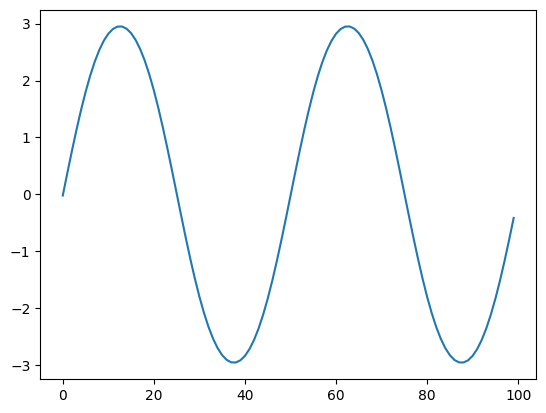

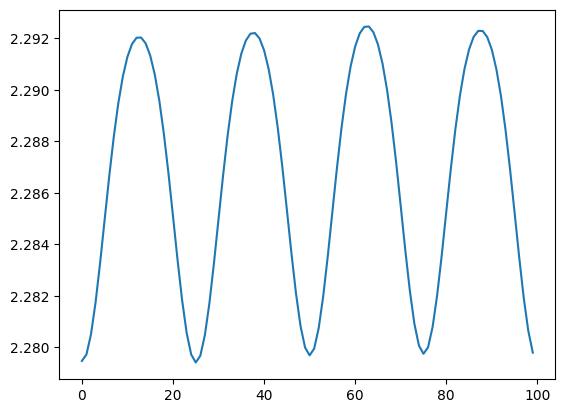

In [117]:
u_ss_5 = np.load('u_ss_5.npy')
e_ss_5 = np.load('e_ss_5.npy')

plt.plot(u_ss_5)
plt.show()

plt.plot(e_ss_5)
plt.show()

5/27 Trying a new kind of coupling:


$\partial_t  u = r u - (k_c^2+\nabla^2)^2 u_0$

$\partial_t E = \alpha_E - \kappa_E U E + D_E \nabla^2 E$

my analysis then says that $<u> = \frac{r \kappa_E}{\alpha_E \kappa_u}$... but doesn't make sense since $<u>=0$. I don't think this will cause $E$ to change with $L$, but I could check. Also not sure if my averaging was valid. 